In [1]:
import pandas as pd

df = pd.read_csv("Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print(df.isnull().sum().sum())
print(df.duplicated().sum())


0
0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isnull().sum())

11


In [5]:
df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "Churn"]].head()

,tenure,MonthlyCharges,Churn
488,0,52.55,No
753,0,20.25,No
936,0,80.85,No
1082,0,25.75,No
1340,0,56.05,No


In [9]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [10]:
df["ChurnFlag"] = df["Churn"].map({"Yes": 1, "No": 0})
df["ChurnFlag"].mean()

np.float64(0.2653698707936959)

In [14]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

In [15]:
df.to_csv("Telco_Clean.csv", index=False)
print(df.shape)

(7043, 22)


In [16]:
import sqlite3

con = sqlite3.connect(":memory:")
df.to_sql("customers", con, index=False, if_exists="replace")

7043

In [17]:
pd.read_sql("""
SELECT COUNT(*) AS total_customers,
       SUM(ChurnFlag) AS churned,
       ROUND(100.0 * SUM(ChurnFlag) / COUNT(*), 1) AS churn_rate_pct
FROM customers
""", con)

,total_customers,churned,churn_rate_pct
0,7043,1869,26.5


In [18]:
pd.read_sql("""
SELECT Contract,
       COUNT(*) AS customers,
       SUM(ChurnFlag) AS churned,
       ROUND(100.0 * SUM(ChurnFlag) / COUNT(*), 1) AS churn_rate_pct
FROM customers
GROUP BY Contract
ORDER BY churn_rate_pct DESC
""", con)

,Contract,customers,churned,churn_rate_pct
0,Month-to-month,3875,1655,42.7
1,One year,1473,166,11.3
2,Two year,1695,48,2.8


In [19]:
pd.read_sql("""
SELECT CASE WHEN tenure <= 12 THEN '1) 0-12 months'
            WHEN tenure <= 24 THEN '2) 13-24 months'
            WHEN tenure <= 48 THEN '3) 25-48 months'
            ELSE '4) 49+ months' END AS tenure_group,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(ChurnFlag) / COUNT(*), 1) AS churn_rate_pct
FROM customers
GROUP BY tenure_group
ORDER BY tenure_group
""", con)

,tenure_group,customers,churn_rate_pct
0,1) 0-12 months,2186,47.4
1,2) 13-24 months,1024,28.7
2,3) 25-48 months,1594,20.4
3,4) 49+ months,2239,9.5


In [20]:
pd.read_sql("""
SELECT CASE WHEN MonthlyCharges < 35 THEN '1) Under 35'
            WHEN MonthlyCharges < 70 THEN '2) 35-70'
            WHEN MonthlyCharges < 90 THEN '3) 70-90'
            ELSE '4) 90+' END AS bill_group,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(ChurnFlag) / COUNT(*), 1) AS churn_rate_pct
FROM customers
GROUP BY bill_group
ORDER BY bill_group
""", con)

,bill_group,customers,churn_rate_pct
0,1) Under 35,1731,10.9
1,2) 35-70,1721,23.6
2,3) 70-90,1847,38.0
3,4) 90+,1744,32.9


In [21]:
import matplotlib.pyplot as plt

def bar_chart(data, x, title, filename):
    plt.figure(figsize=(7, 4))
    bars = plt.bar(data[x], data["churn_rate_pct"], color="#2563EB")
    plt.title(title, fontsize=14, fontweight="bold")
    plt.ylabel("Churn Rate (%)")
    plt.bar_label(bars, fmt="%.1f%%", padding=3)
    plt.ylim(0, data["churn_rate_pct"].max() + 8)
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

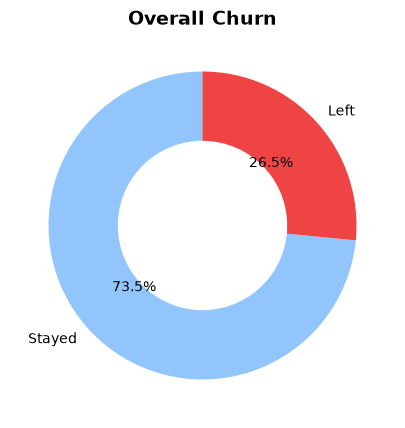

In [22]:
counts = df["Churn"].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(counts, labels=["Stayed", "Left"], autopct="%1.1f%%",
        colors=["#93C5FD", "#EF4444"], startangle=90,
        wedgeprops={"width": 0.45})
plt.title("Overall Churn", fontsize=14, fontweight="bold")
plt.savefig("chart1_overall.png", dpi=150)
plt.show()

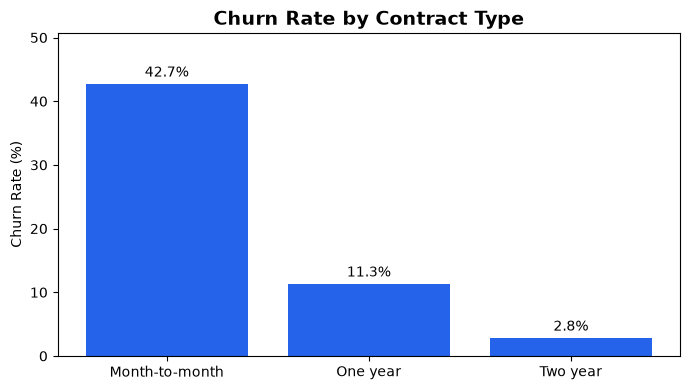

In [23]:
contract = pd.read_sql("""
SELECT Contract,
       ROUND(100.0 * SUM(ChurnFlag) / COUNT(*), 1) AS churn_rate_pct
FROM customers
GROUP BY Contract
ORDER BY churn_rate_pct DESC
""", con)
bar_chart(contract, "Contract", "Churn Rate by Contract Type", "chart2_contract.png")

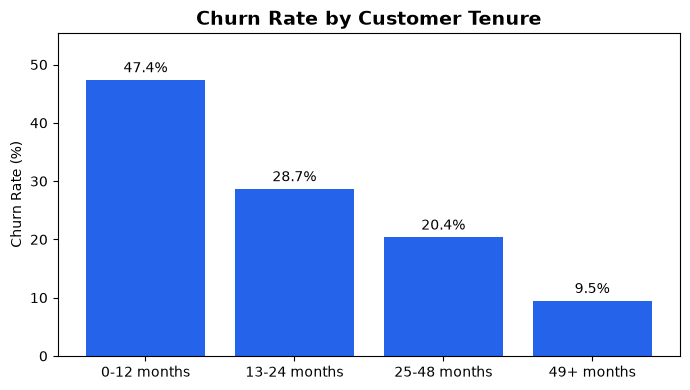

In [24]:
tenure = pd.read_sql("""
SELECT CASE WHEN tenure <= 12 THEN '0-12 months'
            WHEN tenure <= 24 THEN '13-24 months'
            WHEN tenure <= 48 THEN '25-48 months'
            ELSE '49+ months' END AS tenure_group,
       ROUND(100.0 * SUM(ChurnFlag) / COUNT(*), 1) AS churn_rate_pct,
       MIN(tenure) AS m
FROM customers
GROUP BY tenure_group
ORDER BY m
""", con)
bar_chart(tenure, "tenure_group", "Churn Rate by Customer Tenure", "chart3_tenure.png")

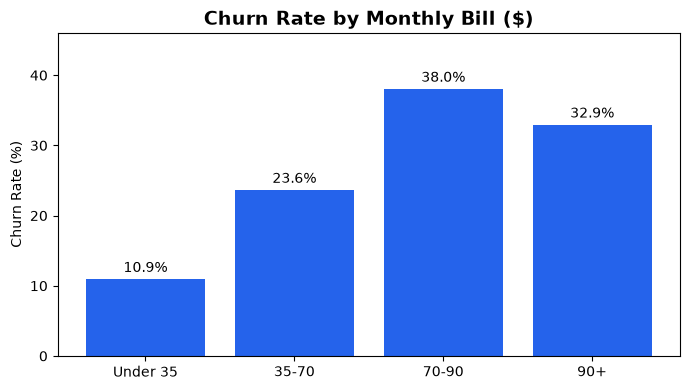

In [25]:
bill = pd.read_sql("""
SELECT CASE WHEN MonthlyCharges < 35 THEN 'Under 35'
            WHEN MonthlyCharges < 70 THEN '35-70'
            WHEN MonthlyCharges < 90 THEN '70-90'
            ELSE '90+' END AS bill_group,
       ROUND(100.0 * SUM(ChurnFlag) / COUNT(*), 1) AS churn_rate_pct,
       MIN(MonthlyCharges) AS m
FROM customers
GROUP BY bill_group
ORDER BY m
""", con)
bar_chart(bill, "bill_group", "Churn Rate by Monthly Bill ($)", "chart4_bill.png")